# Tugas 2 Bagian A: Ekstraksi dan Augmentasi Data DAiSEE

### Identitas Pengerjaan:
- **Mata Kuliah**: Pengolahan Citra Digital
- **Topik**: Ekstraksi Frame Deterministik & Augmentasi Citra Wajah Siswa (*In-The-Wild*)
- **Penyusun**: Iman Dwi Satrio, Ahmad Zaidan

---

### Deskripsi & Tujuan Pengerjaan:
Notebook ini disusun secara mandiri (*self-contained notebook*) untuk menyelesaikan seluruh tahapan pada **Bagian A**, yang mencakup:
1. **Ekstraksi Frame Deterministik**: Mengambil 10 frame representatif secara otomatis dari rekaman video dataset **DAiSEE** (*Dataset for Affective States in E-Environments*) dengan eliminasi heuristik frame non-representatif (15% awal dan 15% akhir video).
2. **Penyimpanan Lossless**: Menyimpan frame mentah dalam format PNG lossless untuk menjaga kualitas piksel asli sebelum proses augmentasi dan pengolahan citra lanjutan.
3. **Kajian Teori & Justifikasi Ilmiah**: Menganalisis landasan ilmiah pemilihan 5 teknik augmentasi citra yang disesuaikan secara khusus dengan karakteristik wajah manusia dalam domain *e-learning*.
4. **Implementasi Transformasi Augmentasi**: Menerapkan 5 teknik augmentasi (*Horizontal Flip*, *Mild Rotation*, *Brightness & Contrast*, *Gaussian Blur*, dan *Coarse Dropout*) menggunakan pustaka `albumentations`.
5. **Visualisasi Grid Komparatif**: Memvisualisasikan seluruh citra asli dan variasi augmentasinya ke dalam matriks grid evaluasi 10 baris × 6 kolom yang siap disalin ke laporan tugas.

In [1]:
# ===================================================================
# IMPORT LIBRARY & KONFIGURASI SEED REPRODUKTIFITAS
# ===================================================================

import os
import cv2
import random
import glob
import numpy as np
import matplotlib.pyplot as plt
import albumentations as A

# 1. Set seed reproduktifitas agar deterministik dan dapat direproduksi ulang
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

# 2. Konfigurasi Path Direktori
VIDEO_DIR = os.path.join("..", "data", "raw", "daisee_videos")
OUTPUT_FRAME_DIR = os.path.join("..", "data", "raw", "daisee_sample")
AUGMENTED_BASE_DIR = os.path.join("..", "data", "augmented")

# 3. Buat folder otomatis jika belum ada
os.makedirs(VIDEO_DIR, exist_ok=True)
os.makedirs(OUTPUT_FRAME_DIR, exist_ok=True)
os.makedirs(AUGMENTED_BASE_DIR, exist_ok=True)

print("[INFO] Library berhasil diimpor & Seed berhasil dikonfigurasi:")
print(f"  - Random Seed         : {RANDOM_SEED}")
print(f"  - Input Video         : {os.path.abspath(VIDEO_DIR)}")
print(f"  - Output Frame Mentah : {os.path.abspath(OUTPUT_FRAME_DIR)}")
print(f"  - Output Augmentasi   : {os.path.abspath(AUGMENTED_BASE_DIR)}")

[INFO] Library berhasil diimpor & Seed berhasil dikonfigurasi:
  - Random Seed         : 42
  - Input Video         : D:\Career Database\04 Projects\Academic\tugas2-pengolahan-citra\data\raw\daisee_videos
  - Output Frame Mentah : D:\Career Database\04 Projects\Academic\tugas2-pengolahan-citra\data\raw\daisee_sample
  - Output Augmentasi   : D:\Career Database\04 Projects\Academic\tugas2-pengolahan-citra\data\augmented


In [2]:
# ===================================================================
# PIPELINE EKSTRAKSI 10 FRAME LANGSUNG
# ===================================================================

# 1. Cari file video (.mp4 dan .avi) secara rekursif di VIDEO_DIR
video_patterns = [
    os.path.join(VIDEO_DIR, "**", "*.mp4"),
    os.path.join(VIDEO_DIR, "**", "*.avi")
]

video_files = []
for pattern in video_patterns:
    video_files.extend(glob.glob(pattern, recursive=True))

# Urutkan secara alfabetis agar urutan awal deterministik lintas OS sebelum di-shuffle
video_files = sorted(video_files)
print(f"[INFO] Total video ditemukan: {len(video_files)}")

TARGET_SAMPLES = 10
extracted_records = []

if not video_files:
    print(f"[PERINGATAN] Tidak ada berkas video (.mp4/.avi) di '{VIDEO_DIR}'.")
    print("Silakan letakkan video DAiSEE di direktori tersebut lalu jalankan ulang sel ini.")
else:
    # Acak urutan video secara deterministik (seed 42)
    random.shuffle(video_files)
    
    video_idx = 0
    max_attempts = max(len(video_files) * 5, 50)
    attempts = 0
    
    print("\n--- Memulai Proses Ekstraksi Deterministik 10 Frame DAiSEE ---")
    while len(extracted_records) < TARGET_SAMPLES and attempts < max_attempts:
        vid_path = video_files[video_idx % len(video_files)]
        video_idx += 1
        attempts += 1
        
        cap = cv2.VideoCapture(vid_path)
        if not cap.isOpened():
            continue
            
        total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        if total_frames <= 0:
            cap.release()
            continue
            
        # Hindari 15% frame awal dan 15% frame akhir (mencegah frame blank / transisi)
        start_frame = int(total_frames * 0.15)
        end_frame = int(total_frames * 0.85)
        
        if end_frame > start_frame:
            random_frame_idx = random.randint(start_frame, end_frame)
            cap.set(cv2.CAP_PROP_POS_FRAMES, random_frame_idx)
            ret, frame = cap.read()
            
            if ret and frame is not None:
                frame_idx_num = len(extracted_records) + 1
                filename = f"daisee_frame_{frame_idx_num:02d}.png"
                output_path = os.path.join(OUTPUT_FRAME_DIR, filename)
                
                # Simpan frame dalam format PNG lossless
                cv2.imwrite(output_path, frame)
                
                height, width = frame.shape[:2]
                channels = frame.shape[2] if len(frame.shape) > 2 else 1
                
                # Cetak log progress setiap frame berhasil diekstrak
                print(f"[{frame_idx_num:02d}/{TARGET_SAMPLES:02d}] "
                        f"Tersimpan: {filename} | "
                        f"Sumber: {os.path.basename(vid_path)} | "
                        f"Frame Idx: {random_frame_idx}/{total_frames} | "
                        f"Resolusi: {width}x{height} (Channels: {channels})")
                        
                extracted_records.append({
                    "filename": filename,
                    "path": output_path,
                    "video": os.path.basename(vid_path),
                    "frame_idx": random_frame_idx,
                    "resolution": (width, height)
                })
        
        cap.release()
        
    print(f"\n[SUKSES] Total {len(extracted_records)} frame berhasil diekstraksi ke '{OUTPUT_FRAME_DIR}'.")

[INFO] Total video ditemukan: 1

--- Memulai Proses Ekstraksi Deterministik 10 Frame DAiSEE ---
[01/10] Tersimpan: daisee_frame_01.png | Sumber: 5100091001.avi | Frame Idx: 208/300 | Resolusi: 640x480 (Channels: 3)
[02/10] Tersimpan: daisee_frame_02.png | Sumber: 5100091001.avi | Frame Idx: 73/300 | Resolusi: 640x480 (Channels: 3)


[03/10] Tersimpan: daisee_frame_03.png | Sumber: 5100091001.avi | Frame Idx: 51/300 | Resolusi: 640x480 (Channels: 3)
[04/10] Tersimpan: daisee_frame_04.png | Sumber: 5100091001.avi | Frame Idx: 234/300 | Resolusi: 640x480 (Channels: 3)
[05/10] Tersimpan: daisee_frame_05.png | Sumber: 5100091001.avi | Frame Idx: 115/300 | Resolusi: 640x480 (Channels: 3)
[06/10] Tersimpan: daisee_frame_06.png | Sumber: 5100091001.avi | Frame Idx: 107/300 | Resolusi: 640x480 (Channels: 3)


[07/10] Tersimpan: daisee_frame_07.png | Sumber: 5100091001.avi | Frame Idx: 102/300 | Resolusi: 640x480 (Channels: 3)
[08/10] Tersimpan: daisee_frame_08.png | Sumber: 5100091001.avi | Frame Idx: 80/300 | Resolusi: 640x480 (Channels: 3)
[09/10] Tersimpan: daisee_frame_09.png | Sumber: 5100091001.avi | Frame Idx: 233/300 | Resolusi: 640x480 (Channels: 3)
[10/10] Tersimpan: daisee_frame_10.png | Sumber: 5100091001.avi | Frame Idx: 71/300 | Resolusi: 640x480 (Channels: 3)

[SUKSES] Total 10 frame berhasil diekstraksi ke '..\data\raw\daisee_sample'.


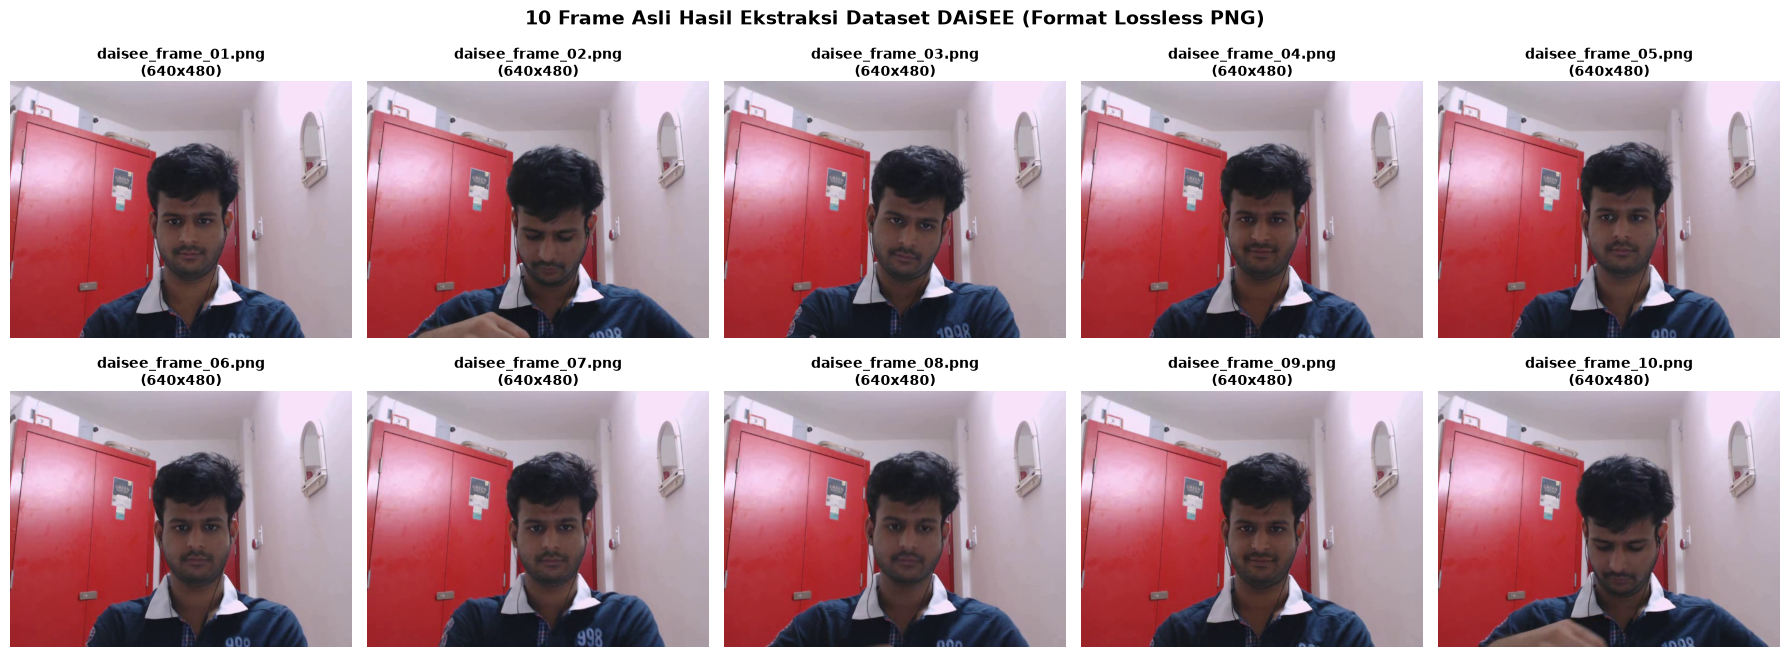

In [3]:
# ===================================================================
# VISUALISASI 10 FRAME ASLI (GRID 2 x 5)
# ===================================================================

frame_paths = [
    os.path.join(OUTPUT_FRAME_DIR, f"daisee_frame_{i:02d}.png")
    for i in range(1, TARGET_SAMPLES + 1)
]

existing_frames = [p for p in frame_paths if os.path.exists(p)]

if not existing_frames:
    print(f"[INFO] Belum ada file frame di '{OUTPUT_FRAME_DIR}'.")
    print("Pastikan Sel 3 telah dijalankan setelah video diletakkan di direktori input.")
else:
    fig, axes = plt.subplots(nrows=2, ncols=5, figsize=(18, 7))
    axes = axes.flatten()
    
    for idx in range(10):
        ax = axes[idx]
        if idx < len(existing_frames):
            fpath = existing_frames[idx]
            img_bgr = cv2.imread(fpath)
            if img_bgr is not None:
                # Konversi BGR OpenCV ke format RGB Matplotlib
                img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
                h, w = img_rgb.shape[:2]
                ax.imshow(img_rgb)
                ax.set_title(f"{os.path.basename(fpath)}\n({w}x{h})", fontsize=10, fontweight='bold', pad=4)
            else:
                ax.text(0.5, 0.5, "Gagal Membaca", ha='center', va='center', color='red')
        else:
            ax.text(0.5, 0.5, f"Slot Kosong\n(Frame {idx+1:02d})", ha='center', va='center', color='gray')
            
        ax.axis('off')
        
    plt.suptitle("10 Frame Asli Hasil Ekstraksi Dataset DAiSEE (Format Lossless PNG)", fontsize=14, fontweight='bold', y=0.98)
    plt.tight_layout()
    plt.show()

# Sel 5: Kajian Teori, Cara Kerja, dan Justifikasi Ilmiah 5 Teknik Augmentasi

Dataset **DAiSEE** (*Dataset for Affective States in E-learning Environments*) merekam ekspresi wajah siswa saat mengikuti pembelajaran daring dalam kondisi bebas (*in-the-wild*). Keadaan afektif yang dinilai mencakup empat label emosi: *Engagement* (keterlibatan), *Boredom* (kebosanan), *Confusion* (kebingungan), dan *Frustration* (frustrasi).

Tujuan utama augmentasi gambar di sini adalah memperkaya variasi data latih (*data diversity*) agar model deep learning tidak mudah menghafal data (*overfitting*), sekaligus memastikan bahwa transformasi yang dilakukan **bersifat menjaga label (*label-preserving*)**-artinya emosi asli siswa tidak boleh berubah atau rusak akibat manipulasi gambar.

Secara sederhana, kita dapat menganalogikan ke-5 teknik augmentasi ini seperti kondisi nyata seorang siswa yang belajar di depan kamera laptop:
1. **Horizontal Flip**: Seperti melihat pantulan di cermin. Struktur wajah simetris terbalik secara horizontal, namun ekspresi wajah seperti tersenyum, mengantuk, atau bingung tetap sama persis.
2. **Mild Rotation (±10°)**: Seperti siswa yang sesekali memiringkan kepala saat berpikir atau membaca materi di layar. Kita batasi rotasinya kecil (maksimal 10 derajat) agar orientasi wajah tetap wajar dan tidak terbalik vertikal.
3. **Brightness & Contrast (±20%)**: Seperti fluktuasi pencahayaan di kamar belajar-misalnya saat lampu dinyalakan, cahaya matahari masuk dari jendela, atau sinar layar laptop menerangi wajah.
4. **Gaussian Blur (Kernel 3-7)**: Seperti kamera web laptop beresolusi rendah (*low-cost webcam*) atau saat kamera sedikit kehilangan fokus karena gerakan siswa.
5. **Coarse Dropout / Cutout (1-3 Kotak Hitam)**: Seperti kondisi saat sebagian wajah terhalang secara alami-misalnya tangan yang menopang dagu, kacamata, mikrofon headset, atau helai rambut yang jatuh di dahi.

---

### Tabel Komparasi 5 Teknik Augmentasi untuk DAiSEE

| No | Nama Teknik | Domain / Kategori Transformasi | Parameter Operasional yang Digunakan | Justifikasi Ilmiah & Relevansi Pembelajaran Daring (*E-Learning*) | Referensi Kunci (Format IEEE / DOI) |
|:--:|:---|:---:|:---|:---|:---|
| **1** | **Horizontal Flip** | Spasial Geometris | Probabilitas $p = 1.0$, Sumbu Y (Refleksi Kiri-Kanan) | Wajah manusia memiliki simetri bilateral alami. Membalik gambar secara horizontal melipatgandakan data tanpa merusak tanda emosi (*label-preserving*). | Shorten & Khoshgoftaar (2019), DOI: 10.1186/s40537-019-0197-0 |
| **2** | **Mild Rotation** | Spasial Geometris | Sudut rotasi $\theta \in [-10^{\circ}, +10^{\circ}]$, Padding `BORDER_REFLECT_101` | Meniru gerakan alami kepala siswa yang sedikit miring saat memperhatikan materi. Sudut kecil menjaga fitur mata dan alis tetap terbaca. | Kumar et al. (2016), arXiv:1609.01885 |
| **3** | **Random Brightness & Contrast** | Intensitas Fotometrik (Piksel) | Rentang $\pm 20\%$ (Faktor Skala $\alpha, \beta \in [-0.2, 0.2]$) | Mensimulasikan perbedaan intensitas lampu ruangan dan pantulan layar laptop, melatih model agar tahan terhadap variasi pencahayaan. | Howard (2013), arXiv:1312.5402 |
| **4** | **Gaussian Blur** | Domain Frekuensi Spasial (Piksel) | Ukuran kernel $k \in \{3, 5, 7\}$, deviasi standar $\sigma \le 1.5$ | Mensimulasikan kualitas kamera web murah atau sedikit *motion blur* saat siswa bergerak, melatih model fokus pada bentuk fitur utama bukan noise tajam. | Shorten & Khoshgoftaar (2019), DOI: 10.1186/s40537-019-0197-0 |
| **5** | **Coarse Dropout** | Oklusi Spasial (Piksel) | 1-3 lubang persegi, ukuran $10\%-20\%$ dimensi gambar, nilai piksel $= 0$ | Mensimulasikan oklusi nyata seperti tangan di dagu atau mikrofon headset. Memaksa model mengenali ekspresi dari beberapa bagian wajah sekaligus. | DeVries & Taylor (2017), arXiv:1708.04552 |



In [4]:
# ===================================================================
# IMPLEMENTASI TRANSFORMASI AUGMENTASI & PENYIMPANAN
# ===================================================================

# 1. Definisikan subdirektori untuk masing-masing teknik augmentasi
aug_subdirs = {
    "tech1_horizontal_flip": os.path.join(AUGMENTED_BASE_DIR, "tech1_horizontal_flip"),
    "tech2_mild_rotation": os.path.join(AUGMENTED_BASE_DIR, "tech2_mild_rotation"),
    "tech3_brightness_contrast": os.path.join(AUGMENTED_BASE_DIR, "tech3_brightness_contrast"),
    "tech4_gaussian_blur": os.path.join(AUGMENTED_BASE_DIR, "tech4_gaussian_blur"),
    "tech5_coarse_dropout": os.path.join(AUGMENTED_BASE_DIR, "tech5_coarse_dropout")
}

for subdir in aug_subdirs.values():
    os.makedirs(subdir, exist_ok=True)

# 2. Definisikan Albumentations Pipeline untuk masing-masing teknik secara deterministik
# Menggunakan seed 42 pada random state untuk menjamin reproduktifitas transformasi
pipelines = {
    "tech1_horizontal_flip": A.Compose([
        A.HorizontalFlip(p=1.0)
    ]),
    "tech2_mild_rotation": A.Compose([
        A.Rotate(limit=(-10, 10), border_mode=cv2.BORDER_REFLECT_101, p=1.0)
    ]),
    "tech3_brightness_contrast": A.Compose([
        A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=1.0)
    ]),
    "tech4_gaussian_blur": A.Compose([
        A.GaussianBlur(blur_limit=(3, 7), sigma_limit=1.5, p=1.0)
    ]),
    "tech5_coarse_dropout": A.Compose([
        A.CoarseDropout(
            num_holes_range=(1, 3),
            hole_height_range=(0.1, 0.2),
            hole_width_range=(0.1, 0.2),
            fill=0,
            p=1.0
        )
    ])
}

# 3. Muat 10 citra asli dari daisee_sample
raw_files = sorted(glob.glob(os.path.join(OUTPUT_FRAME_DIR, "daisee_frame_*.png")))[:10]
print(f"[INFO] Ditemukan {len(raw_files)} citra asli untuk diaugmentasi.")

if not raw_files:
    print("[PERINGATAN] Citra asli belum tersedia di folder sample. Jalankan Sel 3 terlebih dahulu.")
else:
    for img_path in raw_files:
        base_name = os.path.basename(img_path)
        img_bgr = cv2.imread(img_path)
        if img_bgr is None:
            print(f"[ERROR] Gagal membaca berkas: {base_name}")
            continue
            
        # Konversi BGR ke RGB sebelum transformasi Albumentations
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        
        for tech_name, transform in pipelines.items():
            # Transformasi citra
            augmented_rgb = transform(image=img_rgb)["image"]
            
            # Kembalikan ke BGR untuk penyimpanan cv2.imwrite lossless PNG
            augmented_bgr = cv2.cvtColor(augmented_rgb, cv2.COLOR_RGB2BGR)
            out_path = os.path.join(aug_subdirs[tech_name], base_name)
            cv2.imwrite(out_path, augmented_bgr)
            
    print("\n[SUKSES] Seluruh proses augmentasi selesai. Berkas tersimpan di subdirektori:")
    for tech_key, dir_path in aug_subdirs.items():
        total_saved = len(glob.glob(os.path.join(dir_path, '*.png')))
        print(f"  - {tech_key:<25}: {total_saved} citra di {dir_path}")

[INFO] Ditemukan 10 citra asli untuk diaugmentasi.



[SUKSES] Seluruh proses augmentasi selesai. Berkas tersimpan di subdirektori:
  - tech1_horizontal_flip    : 10 citra di ..\data\augmented\tech1_horizontal_flip
  - tech2_mild_rotation      : 10 citra di ..\data\augmented\tech2_mild_rotation
  - tech3_brightness_contrast: 10 citra di ..\data\augmented\tech3_brightness_contrast
  - tech4_gaussian_blur      : 10 citra di ..\data\augmented\tech4_gaussian_blur
  - tech5_coarse_dropout     : 10 citra di ..\data\augmented\tech5_coarse_dropout


[SUKSES] Visualisasi grid 10x6 berhasil disimpan ke: D:\Career Database\04 Projects\Academic\tugas2-pengolahan-citra\reports\figures\augmentation_grid_10x6.png


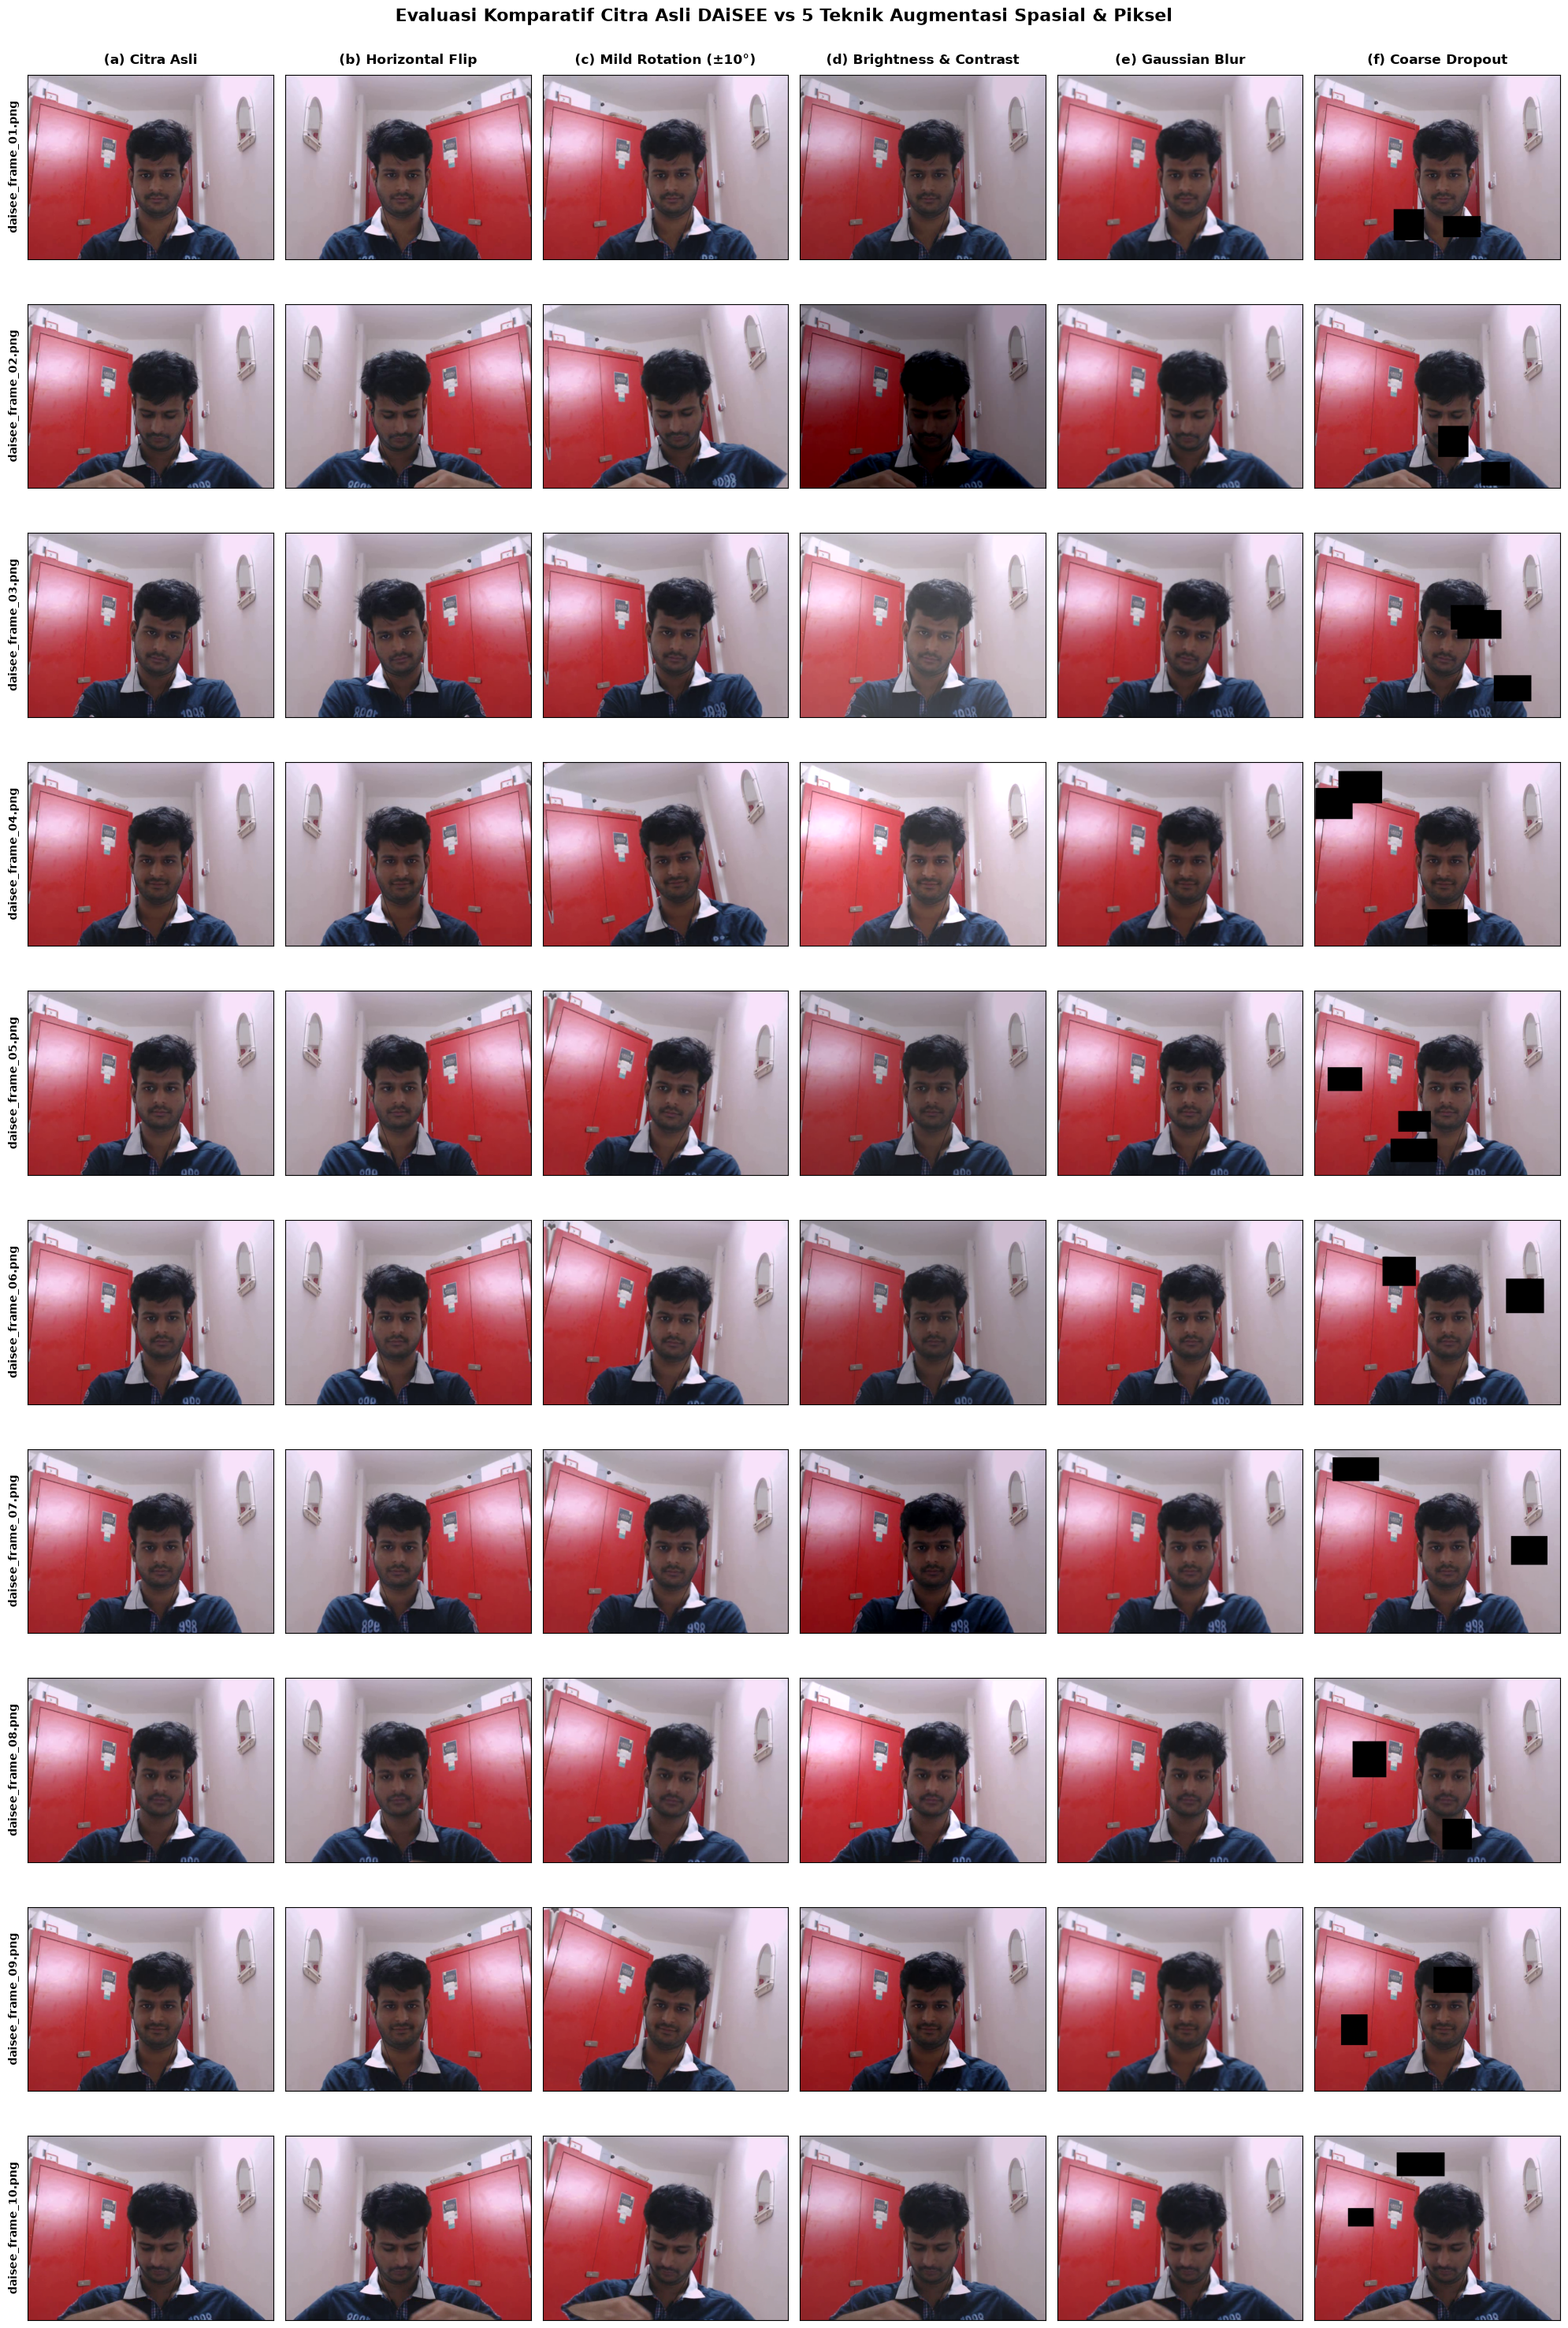

In [5]:
# ===================================================================
# VISUALISASI GRID EVALUASI (10 BARIS x 6 KOLOM)
# ===================================================================

column_titles = [
    "(a) Citra Asli",
    "(b) Horizontal Flip",
    "(c) Mild Rotation (±10°)",
    "(d) Brightness & Contrast",
    "(e) Gaussian Blur",
    "(f) Coarse Dropout"
]

subfolder_keys = [
    None,  # Kolom 1 adalah citra asli
    "tech1_horizontal_flip",
    "tech2_mild_rotation",
    "tech3_brightness_contrast",
    "tech4_gaussian_blur",
    "tech5_coarse_dropout"
]

raw_files = sorted(glob.glob(os.path.join(OUTPUT_FRAME_DIR, "daisee_frame_*.png")))[:10]

if not raw_files:
    print(f"[INFO] Citra asli belum ditemukan di '{OUTPUT_FRAME_DIR}'. Jalankan Sel 3 dan Sel 6 terlebih dahulu.")
else:
    fig, axes = plt.subplots(nrows=10, ncols=6, figsize=(20, 30))
    
    for row_idx in range(10):
        if row_idx < len(raw_files):
            base_name = os.path.basename(raw_files[row_idx])
        else:
            base_name = f"daisee_frame_{row_idx+1:02d}.png"
            
        for col_idx in range(6):
            ax = axes[row_idx, col_idx]
            tech_folder = subfolder_keys[col_idx]
            
            # Tentukan path berkas citra yang akan dimuat
            if tech_folder is None:
                img_file = os.path.join(OUTPUT_FRAME_DIR, base_name)
            else:
                img_file = os.path.join(AUGMENTED_BASE_DIR, tech_folder, base_name)
                
            if os.path.exists(img_file):
                bgr = cv2.imread(img_file)
                if bgr is not None:
                    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
                    ax.imshow(rgb)
                else:
                    ax.text(0.5, 0.5, "Error Read", ha='center', va='center', color='red')
            else:
                ax.text(0.5, 0.5, f"Kosong\n({base_name})", ha='center', va='center', color='gray', fontsize=8)
                
            # Beri judul kolom yang rapi pada baris pertama (Row 0)
            if row_idx == 0:
                ax.set_title(column_titles[col_idx], fontsize=12, fontweight='bold', pad=10)
                
            # Beri label nama file frame pada kolom paling kiri (Col 0)
            if col_idx == 0:
                ax.set_ylabel(base_name, fontsize=10, fontweight='bold', rotation=90, labelpad=8)
                
            # Hilangkan ticks sumbu koordinat agar bersih untuk laporan
            ax.set_xticks([])
            ax.set_yticks([])
            
    plt.suptitle("Evaluasi Komparatif Citra Asli DAiSEE vs 5 Teknik Augmentasi Spasial & Piksel",
                fontsize=16, fontweight='bold', y=0.995)
    plt.tight_layout()
    # Simpan visualisasi grid 10x6 ke folder reports/figures/
    if os.path.exists("reports"):
        rep_fig_dir = os.path.join("reports", "figures")
    elif os.path.exists("../reports"):
        rep_fig_dir = os.path.join("..", "reports", "figures")
    else:
        rep_fig_dir = os.path.abspath(os.path.join("..", "reports", "figures"))
    os.makedirs(rep_fig_dir, exist_ok=True)
    fig_path = os.path.join(rep_fig_dir, "augmentation_grid_10x6.png")
    plt.savefig(fig_path, dpi=150, bbox_inches='tight')
    print(f"[SUKSES] Visualisasi grid 10x6 berhasil disimpan ke: {os.path.abspath(fig_path)}")
    plt.show()
